# AAI - Block 1 - Mini Symposium - Research - Data - Dutch

## 1. Packages Installeren

In [60]:
%pip install -qq --upgrade ipywidgets jupyter pillow pip ultralytics requests tqdm pyyaml

Note: you may need to restart the kernel to use updated packages.


>In deze cel heb ik de benodigde Python-bibliotheken geïnstalleerd en bijgewerkt. Deze bibliotheken zijn noodzakelijk voor het uitvoeren van de code, het verwerken van afbeeldingen, het downloaden van bestanden en het opbouwen van de dataset.

## 2. Packages Importeren

In [61]:
import json
import matplotlib.pyplot as plt
import random
import requests
import shutil
import yaml

from io import BytesIO
from IPython.display import display
from pathlib import Path
from PIL import Image
from tqdm import tqdm

>In deze cel heb ik de geïnstalleerde bibliotheken geïmporteerd. Hiermee zijn verschillende functies beschikbaar gemaakt voor onder andere gegevensverwerking, beeldbewerking, bestandsbeheer en visualisatie.

## 3. Categorieën Selecteren

In [62]:
geselecteerde_categorieën = [
'book', # Boeken
'jersey', # Kleding
'sock', # Kleding
'sweater', # Kleding
'trousers', # Kleding
'underwear', # Kleding
'step_stool', # Krukje
'runner_(carpet)', # Matje
'magazine', # Papier
'shoe'] # Schoenen

print('De volgende categorieën zijn geselecteerd:', geselecteerde_categorieën)

De volgende categorieën zijn geselecteerd: ['book', 'jersey', 'sock', 'sweater', 'trousers', 'underwear', 'step_stool', 'runner_(carpet)', 'magazine', 'shoe']


>In deze cel heb ik de valgevaarlijke objectcategorieën geselecteerd die binnen de dataset worden onderzocht. Er zijn in totaal 10 categorieën geselecteerd:
>
>- Book
>- Jersey
>- Sock
>- Sweater
>- Trousers
>- Underwear
>- Step stool
>- Runner carpet
>- Magazine
>- Shoe
>
>Deze categorieën worden gebruikt als de 10 verschillende klassen binnen de dataset.

## 4. Paden Definiëren

In [63]:
lvis_trainingsset_labels = Path('LVIS - Trainingsset - Labels.json') 
lvis_validatieset_labels = Path('LVIS - Validatieset - Labels.json')
dataset = Path('Dataset')

>In deze cel heb ik de bestandspaden vastgelegd die nodig zijn om de oorspronkelijke LVIS-labelbestanden te benaderen en de gegenereerde dataset op te slaan.

## 5. Categorieën Controleren

In [64]:
with lvis_trainingsset_labels.open(encoding = 'utf-8') as bestand:
    lvis_trainingsset_labels = json.load(bestand)

with lvis_validatieset_labels.open(encoding = 'utf-8') as bestand:
    lvis_validatieset_labels = json.load(bestand)

lvis_categorie_ids = {categorie['name']: categorie['id'] for categorie in lvis_trainingsset_labels['categories']}

for categorie in geselecteerde_categorieën:
    if categorie not in lvis_categorie_ids:
        raise ValueError(f'De volgende categorieën zijn niet gevonden: {categorie}')

yolo_categorie_ids = {lvis_categorie_ids[categorie]: nummer for nummer, categorie in enumerate(geselecteerde_categorieën)}

print('De volgende categorieën zijn gevonden:', geselecteerde_categorieën)

De volgende categorieën zijn gevonden: ['book', 'jersey', 'sock', 'sweater', 'trousers', 'underwear', 'step_stool', 'runner_(carpet)', 'magazine', 'shoe']


>In deze cel heb ik gecontroleerd of de 10 geselecteerde categorieën daadwerkelijk aanwezig zijn in de LVIS-labelbestanden. Vervolgens heb ik de oorspronkelijke categorie-ID's omgezet naar opeenvolgende klasse-ID's die geschikt zijn voor YOLO. Alle 10 geselecteerde categorieën waren succesvol teruggevonden.

## 6. Dataset Creëren of Opschonen

In [65]:
if dataset.exists():
    shutil.rmtree(dataset)

for resolutie in (320, 640, 1280):
    (dataset / f'Testset - {resolutie}x{resolutie}' / 'Afbeeldingen').mkdir(parents = True, exist_ok = True)
    (dataset / f'Testset - {resolutie}x{resolutie}' / 'Labels').mkdir(parents = True, exist_ok = True)

>In deze cel heb ik de bestaande datasetmap verwijderd wanneer deze al aanwezig was. Vervolgens heb ik een nieuwe mappenstructuur aangemaakt waarin de afbeeldingen en bijbehorende labels per resolutie worden opgeslagen. Er zijn 3 afzonderlijke resoluties aangemaakt:
>
>- 320 × 320 pixels
>- 640 × 640 pixels
>- 1280 × 1280 pixels
>
>Per resolutie zijn 2 mappen aangemaakt voor afbeeldingen en labels. Dit resulteert in 6 afzonderlijke opslagmappen.

## 7. Afbeeldingen en Labels Installeren

In [66]:
afbeeldingen = {afbeelding['id']: afbeelding for afbeelding in lvis_trainingsset_labels['images']}
annotaties_per_categorie = {categorie_id: {} for categorie_id in yolo_categorie_ids}

for annotatie in lvis_trainingsset_labels['annotations']:
    if annotatie['category_id'] in yolo_categorie_ids:
        annotaties_per_categorie[annotatie['category_id']].setdefault(annotatie['image_id'], []).append(annotatie)

geselecteerde_afbeeldingen = {}
gebruikte_afbeelding_ids = set()
maximaal_aantal_afbeeldingen_per_categorie = 10

for categorie_id, annotaties in annotaties_per_categorie.items():
    beschikbare_afbeelding_ids = [
        afbeelding_id
        for afbeelding_id in annotaties
        if afbeelding_id not in gebruikte_afbeelding_ids
    ][:maximaal_aantal_afbeeldingen_per_categorie]

    if len(beschikbare_afbeelding_ids) < maximaal_aantal_afbeeldingen_per_categorie:
        raise ValueError(
            f'Categorie {geselecteerde_categorieën[yolo_categorie_ids[categorie_id]]} '
            f'heeft slechts {len(beschikbare_afbeelding_ids)} beschikbare afbeeldingen.')

    for afbeelding_id in beschikbare_afbeelding_ids:
        geselecteerde_afbeeldingen[afbeelding_id] = {
            'category_id': categorie_id,
            'annotaties': annotaties[afbeelding_id]}
        gebruikte_afbeelding_ids.add(afbeelding_id)

aantallen_per_categorie = {categorie_id: 0 for categorie_id in yolo_categorie_ids}

annotaties_per_afbeelding = {}

for annotatie in lvis_trainingsset_labels['annotations']:
    if annotatie['category_id'] in yolo_categorie_ids:
        annotaties_per_afbeelding.setdefault(annotatie['image_id'], []).append(annotatie)

with requests.Session() as sessie:
    for afbeelding_id, selectie in tqdm(geselecteerde_afbeeldingen.items(), desc = 'Installeren'):
        try:
            response = sessie.get(afbeeldingen[afbeelding_id]['coco_url'], timeout = 30)
            response.raise_for_status()

            with Image.open(BytesIO(response.content)) as afbeelding:
                afbeelding = afbeelding.convert('RGB')
                breedte, hoogte = afbeelding.size

                regels = [
                    f'{yolo_categorie_ids[annotatie["category_id"]]} ' + ' '.join(
                        f'{waarde:.6f}' for waarde in [
                            (annotatie['bbox'][0] + annotatie['bbox'][2] / 2) / breedte,
                            (annotatie['bbox'][1] + annotatie['bbox'][3] / 2) / hoogte,
                            annotatie['bbox'][2] / breedte,
                            annotatie['bbox'][3] / hoogte])
                    for annotatie in annotaties_per_afbeelding.get(afbeelding_id, [])
                    if annotatie['bbox'][2] > 0 and annotatie['bbox'][3] > 0]

                if not regels:
                    continue

                for resolutie in (320, 640, 1280):
                    mapnaam = f'Testset - {resolutie}x{resolutie}'

                    afbeelding.resize(
                        (resolutie, resolutie),
                        Image.Resampling.LANCZOS).save(dataset / mapnaam / 'Afbeeldingen' / f'{afbeelding_id}.jpg')

                    (dataset / mapnaam / 'Labels' / f'{afbeelding_id}.txt').write_text('\n'.join(regels), encoding = 'utf-8')

                aantallen_per_categorie[selectie['category_id']] += 1

        except (KeyError, OSError, ValueError, requests.RequestException) as foutmelding:
            print(f'Afbeelding {afbeelding_id} kon niet worden gedownload: {foutmelding}')

Installeren: 100%|██████████| 100/100 [00:23<00:00,  4.20it/s]


>In deze cel heb ik afbeeldingen geselecteerd uit de LVIS-trainingsset op basis van de 10 gekozen categorieën. De bijbehorende annotaties zijn verwerkt en omgezet naar het YOLO-formaat. Vervolgens heb ik de afbeeldingen en labels opgeslagen in de drie verschillende resoluties. Er zijn 100 afbeeldingen succesvol geselecteerd en verwerkt. De 100 afbeeldingen zijn opgeslagen in 3 verschillende resoluties. Hierdoor zijn in totaal 300 afbeeldingsbestanden en 300 bijbehorende labelbestanden gegenereerd.

## 8. YAML Creëren of Opschonen

In [67]:
categorieën = {index: label
               for index, label in enumerate(geselecteerde_categorieën)}

map_yaml = dataset.parent / 'Dataset YAML'
map_yaml.mkdir(parents = True, exist_ok = True)

for resolutie in (320, 640, 1280):
    dataset_yaml = map_yaml / f'Testset - {resolutie}x{resolutie}.yaml'
    mapnaam_yaml = f'Testset - {resolutie}x{resolutie}'

    instellingen = {
        'path': (dataset / mapnaam_yaml).resolve().as_posix(),
        'train': 'Afbeeldingen',
        'val': 'Afbeeldingen',
        'names': categorieën}

    dataset_yaml.write_text(
        yaml.safe_dump(instellingen, sort_keys = False, allow_unicode = True),
        encoding = 'utf-8')

>In deze cel heb ik voor iedere resolutie een afzonderlijk YAML-configuratiebestand aangemaakt. Deze bestanden bevatten de benodigde informatie over de datasetlocatie, de afbeeldingsmappen en de geselecteerde objectcategorieën.Er zijn 3 YAML-configuratiebestanden aangemaakt.
>
>- Testset 320×320
>- Testset 640×640
>- Testset 1280×1280
>
>Elk configuratiebestand bevat 10 objectcategorieën met bijbehorende klasse-ID's. De configuratiebestanden zijn bedoeld om door YOLO te worden ingelezen.

## 9. Dataset Controleren

In [68]:
for resolutie in (320, 640, 1280):
    mapnaam = f"Testset - {resolutie}x{resolutie}"
    afbeeldingen = list((dataset / mapnaam / 'afbeeldingen').glob('*.jpg'))
    labels = list((dataset / mapnaam / 'labels').glob('*.txt'))
    print(f'{mapnaam}: {len(afbeeldingen)} afbeeldingen en {len(labels)} labels.')

Testset - 320x320: 100 afbeeldingen en 100 labels.
Testset - 640x640: 100 afbeeldingen en 100 labels.
Testset - 1280x1280: 100 afbeeldingen en 100 labels.


> In deze cel heb ik gecontroleerd of de afbeeldingen en bijbehorende labelbestanden daadwerkelijk aanwezig zijn in de aangemaakte datasetmappen. Hiervoor heb ik per resolutie het aantal JPG- en TXT-bestanden geteld. Voor iedere resolutie is het aantal afbeeldingen gelijk aan het aantal labelbestanden. Hiermee is gecontroleerd dat beide bestandstypen in gelijke aantallen aanwezig zijn.

## 10. Dataset Verkennen

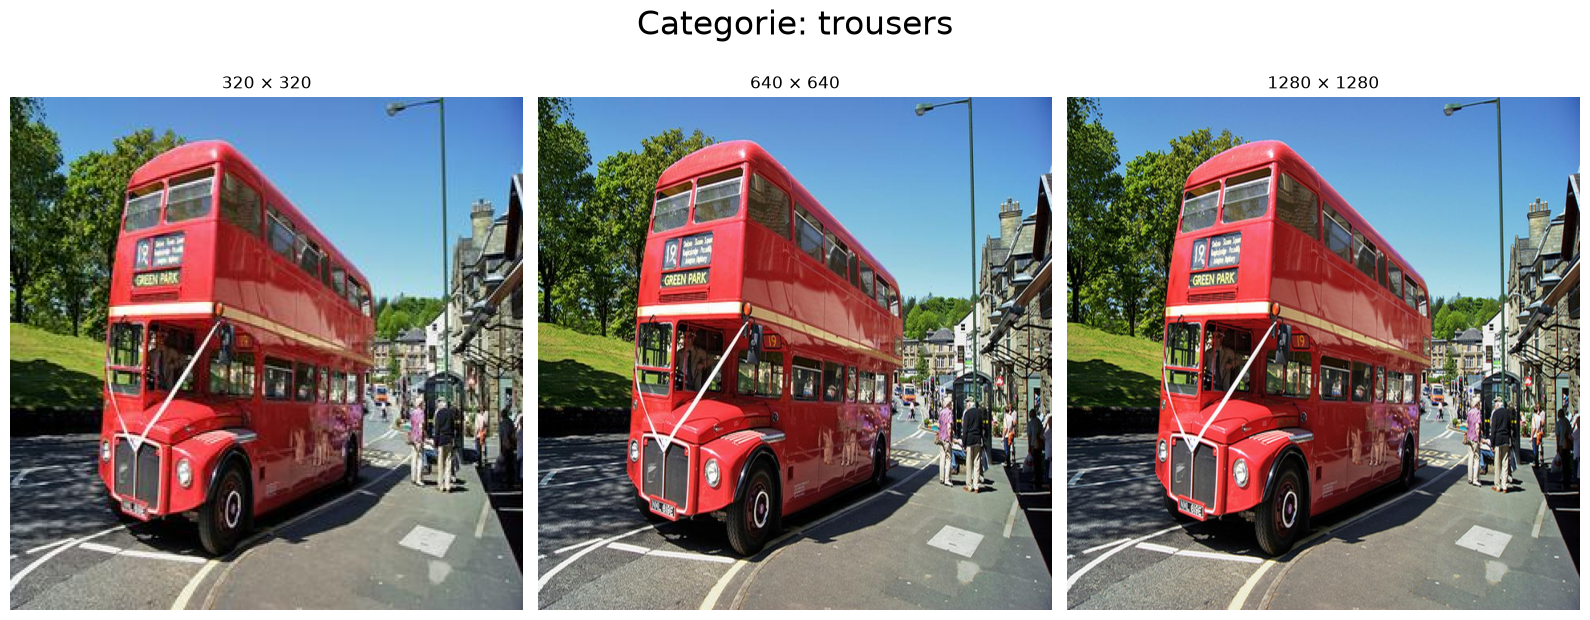

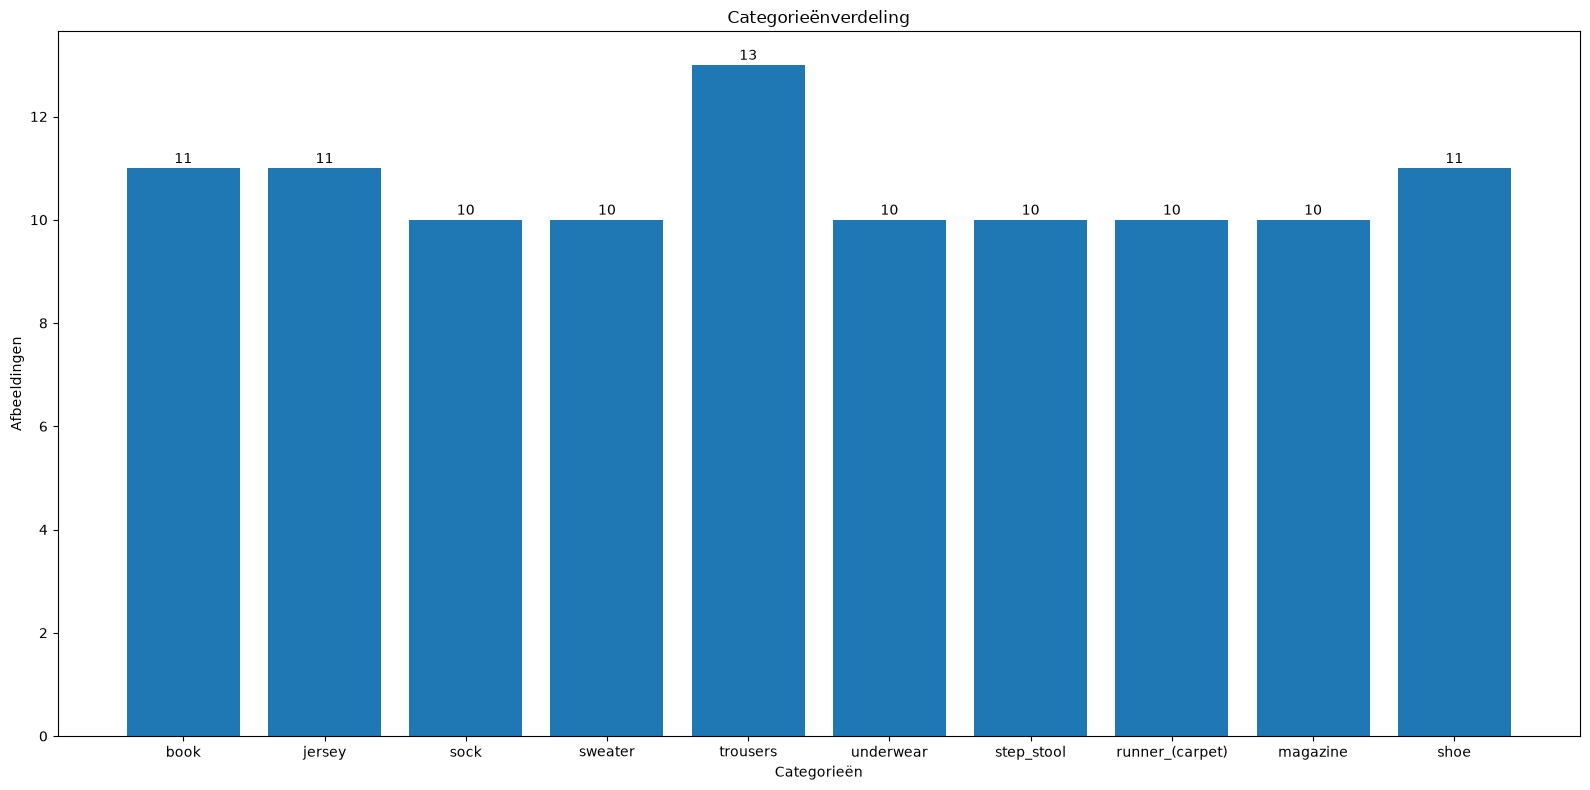

In [69]:
resoluties = (320, 640, 1280)
voorbeeld = next((dataset / 'Testset - 640x640' / 'Labels').glob('*.txt'), None)

if voorbeeld and voorbeeld.read_text().strip():
    afbeelding_id = voorbeeld.stem
    categorie_index = int(voorbeeld.read_text().split()[0])
    categorie = geselecteerde_categorieën[categorie_index]

    figuur, assen = plt.subplots(1, 3, figsize = (16, 8))
    figuur.suptitle(f'Categorie: {categorie}', fontsize = 24, y = 0.9)

    for assen, resolutie in zip(assen, resoluties):
        pad = dataset / f'Testset - {resolutie}x{resolutie}' / 'Afbeeldingen' / f'{afbeelding_id}.jpg'
        assen.imshow(Image.open(pad))
        assen.set_title(f'{resolutie} × {resolutie}')
        assen.axis('off')

    plt.tight_layout()
    plt.show()

labelbestanden = list((dataset / 'Testset - 640x640' / 'Labels').glob('*.txt'))
aantallen = [sum(any(regel.strip() and int(regel.split()[0]) == categorie_index for regel in labelbestand.read_text().splitlines()) for labelbestand in labelbestanden) for categorie_index in range(len(geselecteerde_categorieën))]

plt.figure(figsize = (16, 8))
plt.bar(geselecteerde_categorieën, aantallen)
plt.ylabel('Afbeeldingen')
plt.xlabel('Categorieën')
plt.title('Categorieënverdeling')

for categorie_index, aantal in enumerate(aantallen):
    plt.text(categorie_index, aantal + 0.1, str(aantal), ha = 'center')

plt.tight_layout()
plt.show()

> In deze cel heb ik de gegenereerde dataset visueel onderzocht. Hiervoor heb ik dezelfde voorbeeldafbeelding weergegeven op de drie verschillende resoluties. Daarnaast heb ik een staafdiagram gegenereerd om de verdeling van de geselecteerde objectcategorieën inzichtelijk te maken. De categorieënverdeling heeft de volgende resultaten opgeleverd:
>
>  | Categorie       | Aantal afbeeldingen |
>|-----------------|--------------------:|
>| Book            | 11 |
>| Jersey          | 11 |
>| Sock            | 10 |
>| Sweater         | 10 |
>| Trousers        | 13 |
>| Underwear       | 10 |
>| Step stool      | 10 |
>| Runner carpet   | 10 |
>| Magazine        | 10 |
>| Shoe            | 11 |
>| **Totaal**      | **106** |
>
>De categorie Trousers heeft met 13 afbeeldingen de hoogste vertegenwoordiging. De categorieën Book, Jersey en Shoe volgen met ieder 11 afbeeldingen. De som van 106 categorievoorkomens is hoger dan de 100 unieke afbeeldingen, omdat één afbeelding meerdere geselecteerde categorieën kan bevatten. De grafiek geeft daarmee de aanwezigheid van categorieën per afbeelding weer en niet het aantal unieke afbeeldingen in de dataset.